# YOLO11s · Skenario Sintetis 100% (model pembanding)

Notebook ini melatih dan mengevaluasi **YOLO11s** pada skenario **sintetis 100%**, yaitu 700 citra siang hari ditambah 700 citra malam sintetis CycleGAN-Turbo (100% dari jumlah citra latih asli), lalu diaugmentasi 3×. YOLO11s dipakai sebagai model pembanding untuk melihat apakah pengaruh rasio data sintetis yang ditemukan pada YOLOv12 juga muncul pada arsitektur lain. Seluruh pengaturan sama dengan eksperimen YOLOv12, kecuali model awalnya.

| Pengaturan | Nilai |
|---|---|
| Model awal | `yolo11s.pt` (pretrained COCO, 9,41 juta parameter) |
| Dataset (Kaggle) | `pororozagi/aug-cycle` |
| Data latih / validasi / uji | 4.200 / 200 / 100 citra |
| Epoch | 50 |
| Ukuran citra | 640 × 640 |
| Batch | 16 |
| Optimizer | SGD (lr0 = 0,01, momentum = 0,937, weight decay = 0,0005) |
| Nama run | `yolo11s_sintetis100` |

**Hasil pada data uji** (100 citra malam NPD, 166 objek):

| Precision | Recall | mAP@0.5 | mAP@0.5:0.95 |
|---|---|---|---|
| 0,7804 | 0,5542 | 0,5979 | 0,2971 |

Seluruh bobot, kurva, dan ringkasan metrik disimpan ke Google Drive pada folder `MyDrive/Output Yolo/SOTA/yolo11s_sintetis100`.

## 1. Cek GPU

Pelatihan dijalankan pada GPU Tesla T4 di Google Colab. Pastikan runtime sudah diatur ke GPU melalui **Runtime → Change runtime type → T4 GPU**.

In [1]:
!nvidia-smi

Fri Oct 23 14:10:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   43C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Kunci versi PyTorch

Versi PyTorch bawaan Colab dapat berubah sewaktu-waktu. Sel berikut memasang torch 2.9.0 agar lingkungan sama dengan seluruh eksperimen. Setelah instalasi, runtime perlu dimulai ulang supaya versi baru termuat.

> Jalankan dua sel di bawah ini **satu kali**. Pesan *"Your session crashed"* setelah sel kedua adalah hal yang wajar. Setelah itu, lanjutkan dari bagian **3. Instal dependensi** (jangan menggunakan *Run all* dari atas).

In [2]:
!pip install -q torch==2.9.0 torchvision==0.24.0 torchaudio==2.9.0 --index-url https://download.pytorch.org/whl/cu128

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 142.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 954.8/954.8 kB 244.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 172.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 706.8/706.8 MB 63.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 73.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.1/193.1 MB 108.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.6/63.6 MB 122.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 267.5/267.5 MB 80.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 288.2/288.2 MB 86.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 287.2/287.2 MB 84.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 322.3/322.3 MB 78.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 124.7/124.7 MB 94.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
# Mulai ulang runtime agar torch 2.9.0 termuat
import os
os.kill(os.getpid(), 9)

## 3. Instal dependensi

Model pembanding dilatih dengan paket yang **sama persis** dengan eksperimen YOLOv12, yaitu repositori `sunsmarterjie/yolov12` (fork Ultralytics 8.3.63) yang dikunci ke commit `3bca22b`. Paket ini juga dapat memuat bobot YOLOv8 dan YOLO11, sehingga perbedaan hasil hanya berasal dari arsitektur model, bukan dari versi pustaka.

Sel kedua memeriksa versi lingkungan dan akan berhenti dengan pesan kesalahan bila ada versi yang tidak sesuai.

In [1]:
!pip install -q "git+https://github.com/sunsmarterjie/yolov12.git@3bca22b336e96cfdabfec4c062b84eef210e9563"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import sys, torch, ultralytics

print("Python      :", sys.version.split()[0])
print("Torch       :", torch.__version__, "| CUDA:", torch.version.cuda)
print("Ultralytics :", ultralytics.__version__)
print("GPU         :", torch.cuda.get_device_name(0))

assert torch.__version__.startswith("2.9.0"), f"Versi torch tidak sesuai: {torch.__version__}"
assert ultralytics.__version__ == "8.3.63",   f"Versi Ultralytics tidak sesuai: {ultralytics.__version__}"
assert "T4" in torch.cuda.get_device_name(0), f"GPU bukan T4: {torch.cuda.get_device_name(0)}"

print("\nLingkungan sesuai dengan konfigurasi eksperimen.")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/yolov12/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
FlashAttention is not available on this device. Using scaled_dot_product_attention instead.
Python      : 3.13.15
Torch       : 2.9.0+cu128 | CUDA: 12.8
Ultralytics : 8.3.63
GPU         : Tesla T4

Lingkungan sesuai dengan konfigurasi eksperimen.


## 4. Konfigurasi eksperimen

Seluruh nama yang berbeda antar-notebook dikumpulkan di sel ini. Sel lain tidak perlu diubah.

In [3]:
MODEL_WEIGHTS = "yolo11s.pt"              # model pembanding
DATASET_SLUG  = "pororozagi/aug-cycle"    # skenario data latih (Kaggle)
SCENARIO      = "Sintetis 100% (700 citra siang + 700 citra malam sintetis, augmentasi 3x)"
RUN_NAME      = "yolo11s_sintetis100"     # nama folder hasil pelatihan

EXPORT_PATH   = "/content/dataset"
DATA_YAML     = "/content/data_ready.yaml"

# Lokasi penyimpanan hasil di Google Drive
OUTPUT_GROUP  = "SOTA"                    # Baseline / 50 Sintetis / 100 Sintetis / SOTA
OUTPUT_DIR    = f"/content/drive/MyDrive/Output Yolo/{OUTPUT_GROUP}/{RUN_NAME}"

## 5. Unduh dataset dari Kaggle

Dataset diunduh dari Kaggle menggunakan kredensial yang disimpan di **Colab Secrets** (`KAGGLE_USERNAME` dan `KAGGLE_KEY`). Setelah diekstrak, path pada `data.yaml` ditulis ulang menjadi path absolut, lalu jumlah citra dan label pada setiap split diperiksa.

In [4]:
import os
import yaml
from google.colab import userdata

# 1. Kredensial Kaggle dari Colab Secrets
os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')

# 2. Unduh dan ekstrak dataset
if not os.path.exists(EXPORT_PATH):
    print("⏳ Sedang mendownload dataset...")
    !kaggle datasets download -d {DATASET_SLUG} -p {EXPORT_PATH} --unzip
    print("✅ Download selesai.")
else:
    print("ℹ️ Dataset sudah ada.")

# 3. Cari folder root dataset (yang berisi train dan valid)
actual_base_path = EXPORT_PATH
for root, dirs, files in os.walk(EXPORT_PATH):
    if 'train' in dirs and 'valid' in dirs:
        actual_base_path = root
        break
print(f"📍 Root dataset ditemukan di: {actual_base_path}")

# 4. Tulis ulang data.yaml dengan path absolut
yaml_src = None
for root, dirs, files in os.walk(EXPORT_PATH):
    for f in files:
        if f.endswith('.yaml'):
            yaml_src = os.path.join(root, f)
            break

if yaml_src:
    with open(yaml_src, 'r') as f:
        data = yaml.safe_load(f)

    data['train'] = os.path.join(actual_base_path, 'train', 'images')
    data['val']   = os.path.join(actual_base_path, 'valid', 'images')
    data['test']  = os.path.join(actual_base_path, 'test', 'images')

    with open(DATA_YAML, 'w') as f:
        yaml.dump(data, f)
    print(f"✅ YAML diperbaiki: {DATA_YAML}")
else:
    print("❌ ERROR: File .yaml tidak ditemukan!")

# 5. Periksa jumlah citra dan label pada setiap split
print("\n" + "="*30)
print("📊 LAPORAN DATASET")
print("="*30)

for split in ['train', 'valid', 'test']:
    img_dir = os.path.join(actual_base_path, split, 'images')
    lbl_dir = os.path.join(actual_base_path, split, 'labels')

    if os.path.exists(img_dir) and os.path.exists(lbl_dir):
        n_imgs = len([f for f in os.listdir(img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
        n_lbls = len([f for f in os.listdir(lbl_dir) if f.endswith('.txt')])

        status = "✅ MATCH" if n_imgs == n_lbls else "❌ MISMATCH"
        print(f"[{split.upper()}]")
        print(f"  - Gambar: {n_imgs}")
        print(f"  - Label : {n_lbls}")
        print(f"  - Status: {status}")

        if n_imgs == 0:
            print(f"  ⚠️ PERINGATAN: Folder {split} kosong!")
    else:
        print(f"❌ [{split.upper()}] Folder images/labels tidak ditemukan!")

print("="*30)

⏳ Sedang mendownload dataset...
Dataset URL: https://www.kaggle.com/datasets/pororozagi/aug-cycle
License(s): unknown
100% 313M/313M [00:03<00:00, 89.4MB/s]

✅ Download selesai.
📍 Root dataset ditemukan di: /content/dataset/The aug
✅ YAML diperbaiki: /content/data_ready.yaml

📊 LAPORAN DATASET
[TRAIN]
  - Gambar: 4200
  - Label : 4200
  - Status: ✅ MATCH
[VALID]
  - Gambar: 200
  - Label : 200
  - Status: ✅ MATCH
[TEST]
  - Gambar: 100
  - Label : 100
  - Status: ✅ MATCH


**Insight.** Jumlah citra dan label cocok pada ketiga split.
- **Latih:** 4.200 citra, berasal dari 700 citra siang asli dan 700 citra malam sintetis CycleGAN-Turbo yang masing-masing menghasilkan tiga versi augmentasi.
- **Validasi:** 200 citra (100 siang dan 100 malam).
- **Uji:** 100 citra malam dari NPD.

Data validasi dan data uji sama dengan skenario lain, sehingga perbedaan hasil hanya berasal dari data latih.

## 6. Pelatihan model

Model diinisialisasi dari bobot pretrained COCO, lalu di-*fine-tune* selama 50 epoch. Hyperparameter pada sel ini sama untuk seluruh 15 konfigurasi (tabel hyperparameter pelatihan di Bab 4 naskah), sedangkan hyperparameter lain mengikuti nilai bawaan Ultralytics, termasuk `seed=0`. Bobot dengan nilai *fitness* validasi tertinggi disimpan sebagai `best.pt`.

In [5]:
from ultralytics import YOLO
import torch
import os

# 1. Cek perangkat
device_to_use = 0 if torch.cuda.is_available() else 'cpu'
if device_to_use == 'cpu':
    print("⚠️ PERINGATAN: GPU tidak terdeteksi. Training akan sangat lambat!")
else:
    print(f"✅ GPU Terdeteksi: {torch.cuda.get_device_name(0)}")

# 2. Muat bobot pretrained COCO sebagai titik awal fine-tuning
model = YOLO(MODEL_WEIGHTS)

# 3. Pelatihan
assert os.path.exists(DATA_YAML), f"{DATA_YAML} tidak ditemukan. Jalankan sel unduh dataset terlebih dahulu."

results = model.train(
    data=DATA_YAML,
    epochs=50,
    imgsz=640,
    batch=16,
    optimizer='SGD',
    lr0=0.01,
    momentum=0.937,
    weight_decay=0.0005,
    device=device_to_use,
    name=RUN_NAME
)

✅ GPU Terdeteksi: Tesla T4


100%|██████████| 18.4M/18.4M [00:00<00:00, 92.2MB/s]


New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=yolo11s.pt, data=/content/data_ready.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=0, workers=8, project=None, name=yolo11s_sintetis100, exist_ok=False, pretrained=True, optimizer=SGD, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, sav

100%|██████████| 755k/755k [00:00<00:00, 23.1MB/s]


Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       928  ultralytics.nn.modules.conv.Conv             [3, 32, 3, 2]                 
  1                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  2                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  3                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  4                  -1  1    103360  ultralytics.nn.modules.block.C3k2            [128, 256, 1, False, 0.25]    
  5                  -1  1    590336  ultralytics.nn.modules.conv.Conv             [256, 256, 3, 2]              
  6                  -1  1    346112  ultralytics.nn.modules.block.C3k2            [256, 256, 1, True]           
  7                  -1  1   1180672  ultralytics

...

      50/50      4.47G     0.8063      0.474      1.097         15        640: 100%|██████████| 263/263 [01:16<00:00,  3.42it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:02<00:00,  3.44it/s]

                   all        200        409      0.742      0.584      0.633      0.343



50 epochs completed in 1.142 hours.
Optimizer stripped from runs/detect/yolo11s_sintetis100/weights/last.pt, 19.2MB
Optimizer stripped from runs/detect/yolo11s_sintetis100/weights/best.pt, 19.2MB

Validating runs/detect/yolo11s_sintetis100/weights/best.pt...
Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 238 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:04<00:00,  1.67it/s]


                   all        200        409      0.708      0.634      0.646      0.353
Speed: 0.3ms preprocess, 6.9ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to runs/detect/yolo11s_sintetis100


**Insight.**
- Pelatihan 50 epoch selesai dalam **1,382 jam** (sekitar 1 jam 23 menit) pada GPU T4.
- Evaluasi `best.pt` pada data validasi menghasilkan Precision 0,708, Recall 0,634, mAP@0.5 **0,646**, dan mAP@0.5:0.95 **0,353**.
- Model berisi 9,41 juta parameter (fused) dan kecepatan inferensi pada data validasi sekitar 5,3 ms per citra.

## 7. Kurva pelatihan dan validasi

In [6]:
import os
import glob
import matplotlib.pyplot as plt
import cv2

results_dir = f'runs/detect/{RUN_NAME}'
if not os.path.exists(results_dir):
    # Gunakan folder run terbaru bila nama di atas tidak ditemukan
    results_dir = max(glob.glob('runs/detect/*'), key=os.path.getmtime)

print(f"📂 Mengambil hasil dari: {results_dir}")

📂 Mengambil hasil dari: runs/detect/yolo11s_sintetis100


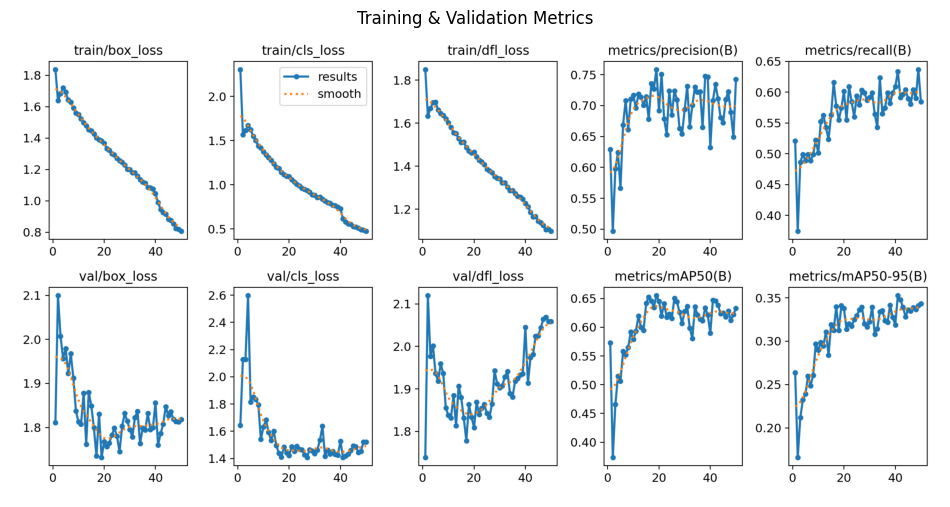

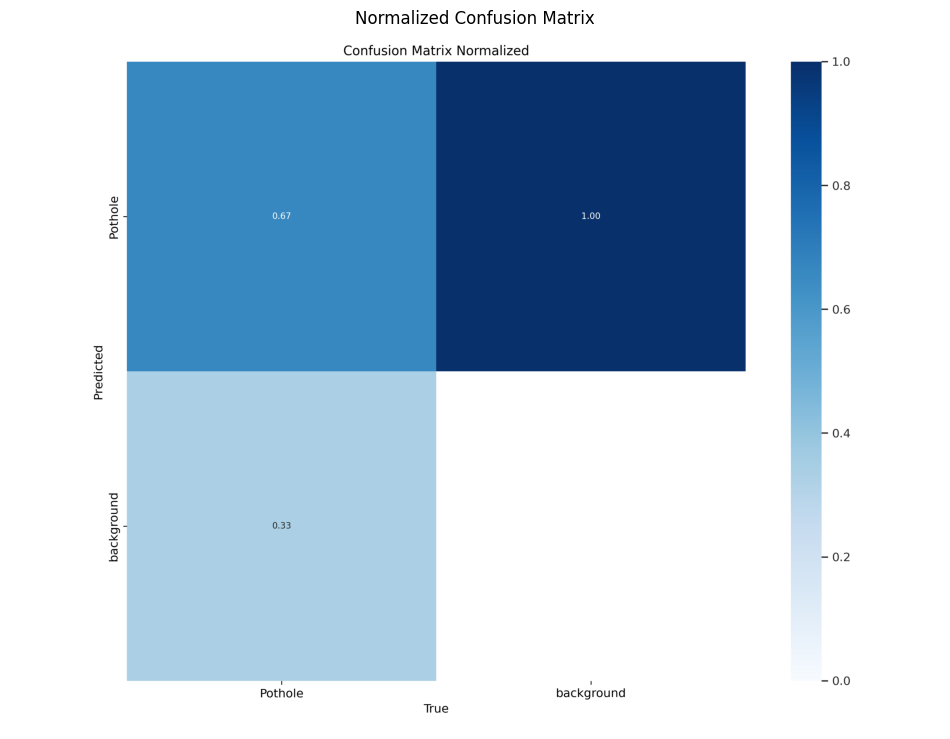

In [7]:
def show_image(path, title):
    if os.path.exists(path):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(12, 10))
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ File {path} tidak ditemukan.")

# Grafik loss dan metrik per epoch
show_image(f"{results_dir}/results.png", "Training & Validation Metrics")

# Confusion matrix ternormalisasi pada data validasi
show_image(f"{results_dir}/confusion_matrix_normalized.png", "Normalized Confusion Matrix")

**Catatan.** Grafik ini tidak ditampilkan pada notebook asli, sehingga belum ada outputnya. Grafik akan muncul saat notebook dijalankan ulang.

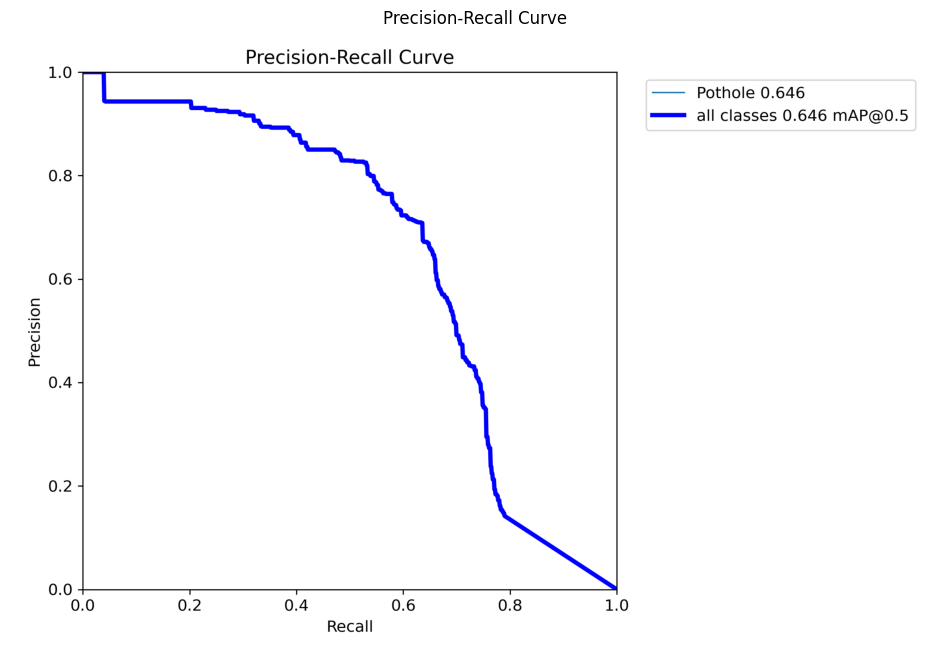

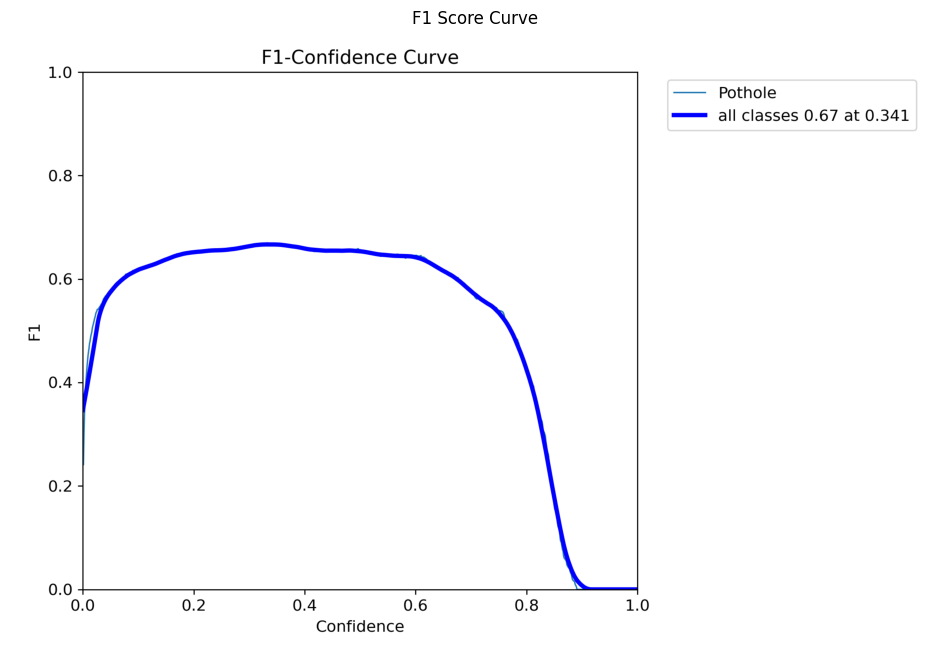

In [8]:
# Kurva Precision-Recall dan F1-confidence pada data validasi
show_image(f"{results_dir}/PR_curve.png", "Precision-Recall Curve")
show_image(f"{results_dir}/F1_curve.png", "F1 Score Curve")

**Catatan.** Grafik ini tidak ditampilkan pada notebook asli, sehingga belum ada outputnya. Grafik akan muncul saat notebook dijalankan ulang.

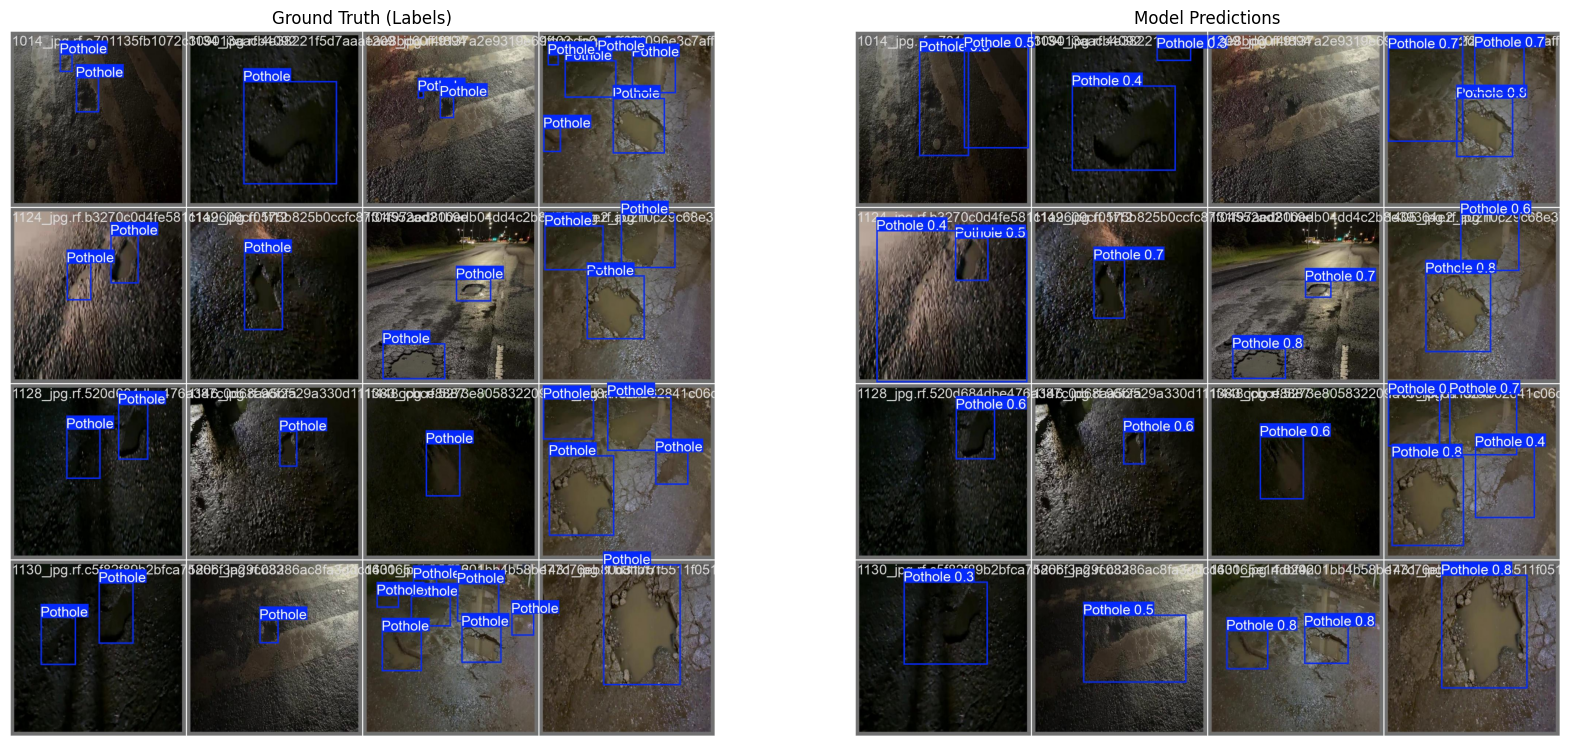

In [9]:
# Perbandingan label asli dan prediksi pada batch pertama data validasi
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

img_labels = cv2.imread(f"{results_dir}/val_batch0_labels.jpg")
axes[0].imshow(cv2.cvtColor(img_labels, cv2.COLOR_BGR2RGB))
axes[0].set_title("Ground Truth (Labels)")
axes[0].axis('off')

img_pred = cv2.imread(f"{results_dir}/val_batch0_pred.jpg")
axes[1].imshow(cv2.cvtColor(img_pred, cv2.COLOR_BGR2RGB))
axes[1].set_title("Model Predictions")
axes[1].axis('off')

plt.show()

### Kurva per epoch dari `results.csv`

Grafik bawaan Ultralytics digambar ulang dari `results.csv` agar loss latih dan loss validasi berada pada satu panel untuk setiap komponen, serta epoch terbaik ditandai secara eksplisit. Epoch terbaik ditentukan dengan nilai *fitness* yang sama dengan Ultralytics, yaitu 0,1 × mAP@0.5 + 0,9 × mAP@0.5:0.95.

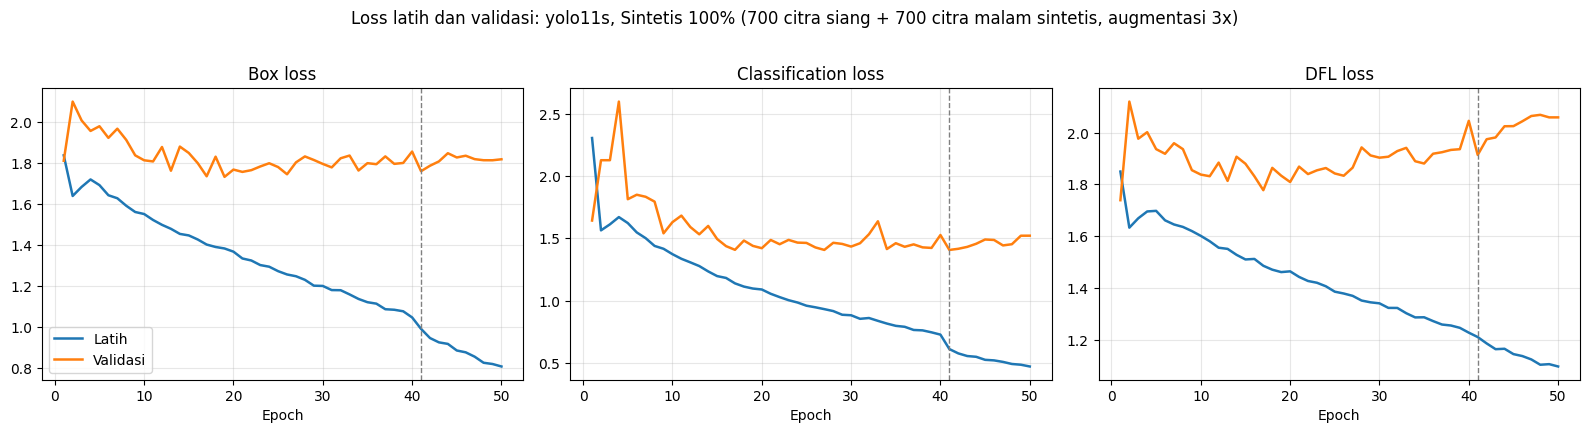

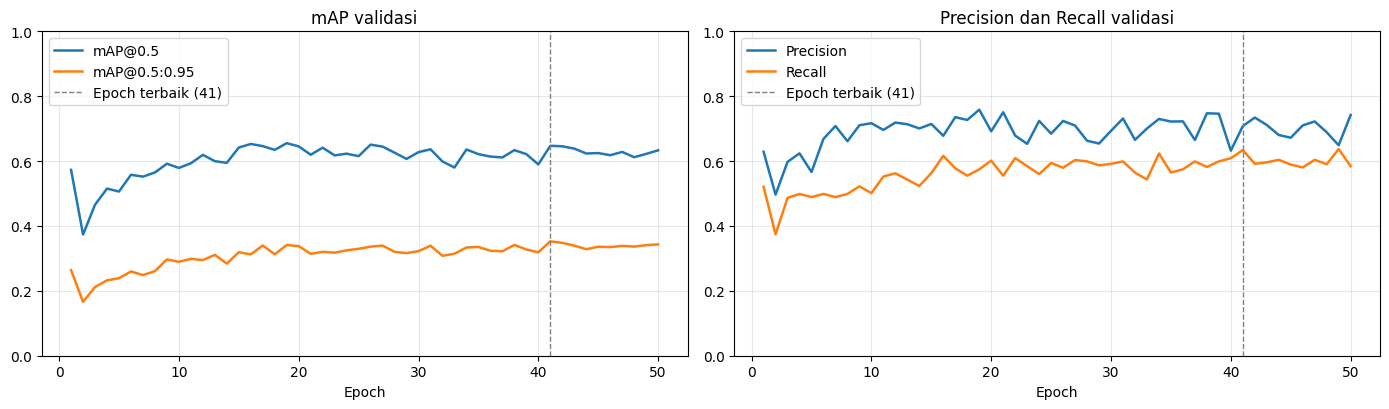

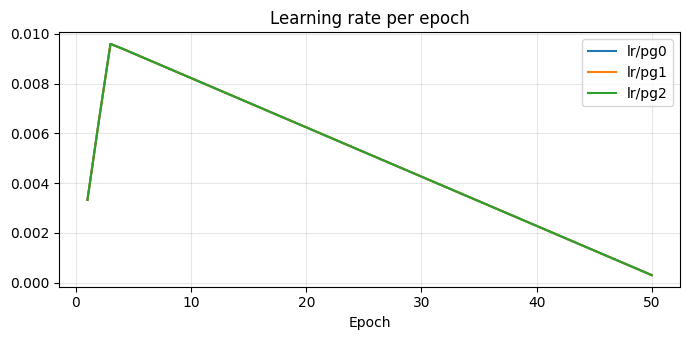

Epoch terbaik: 41
metrics/precision(B)    0.7078
metrics/recall(B)       0.6339
metrics/mAP50(B)        0.6471
metrics/mAP50-95(B)     0.3527


In [10]:
import pandas as pd

hist = pd.read_csv(f"{results_dir}/results.csv")
hist.columns = hist.columns.str.strip()
epochs = hist["epoch"]

fitness = 0.1 * hist["metrics/mAP50(B)"] + 0.9 * hist["metrics/mAP50-95(B)"]
best_idx = int(fitness.idxmax())
best_epoch = int(epochs[best_idx])

# Loss latih vs validasi
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, comp, title in zip(axes, ["box", "cls", "dfl"], ["Box loss", "Classification loss", "DFL loss"]):
    ax.plot(epochs, hist[f"train/{comp}_loss"], label="Latih", lw=1.8)
    ax.plot(epochs, hist[f"val/{comp}_loss"], label="Validasi", lw=1.8)
    ax.axvline(best_epoch, color="grey", ls="--", lw=1)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.3)
axes[0].legend()
fig.suptitle(f"Loss latih dan validasi: {MODEL_WEIGHTS.replace('.pt', '')}, {SCENARIO}", y=1.02)
plt.tight_layout(); plt.show()

# Metrik validasi per epoch
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(epochs, hist["metrics/mAP50(B)"], label="mAP@0.5", lw=1.8)
axes[0].plot(epochs, hist["metrics/mAP50-95(B)"], label="mAP@0.5:0.95", lw=1.8)
axes[1].plot(epochs, hist["metrics/precision(B)"], label="Precision", lw=1.8)
axes[1].plot(epochs, hist["metrics/recall(B)"], label="Recall", lw=1.8)
for ax, title in zip(axes, ["mAP validasi", "Precision dan Recall validasi"]):
    ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Epoch terbaik ({best_epoch})")
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

# Learning rate
lr_cols = [c for c in hist.columns if c.startswith("lr/")]
plt.figure(figsize=(7, 3.5))
for c in lr_cols:
    plt.plot(epochs, hist[c], label=c)
plt.title("Learning rate per epoch"); plt.xlabel("Epoch"); plt.grid(alpha=0.3); plt.legend()
plt.tight_layout(); plt.show()

print(f"Epoch terbaik: {best_epoch}")
print(hist.loc[best_idx, ["metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].round(4).to_string())

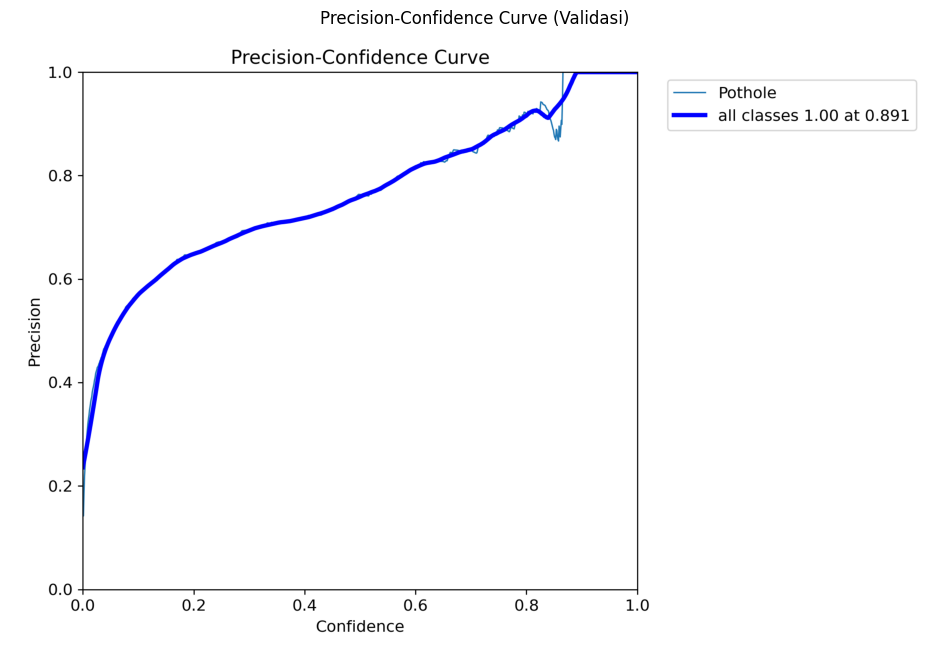

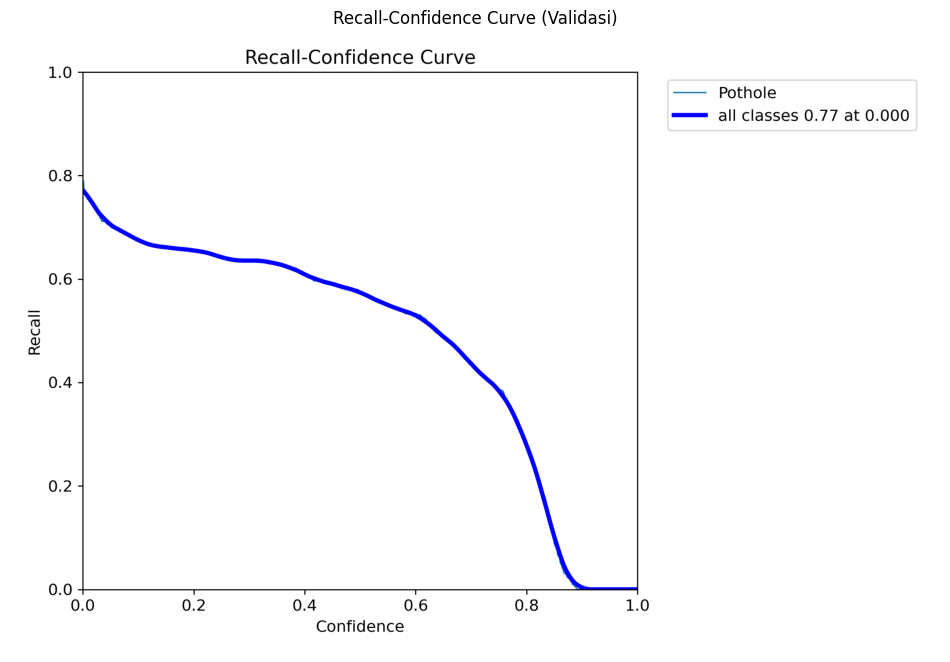

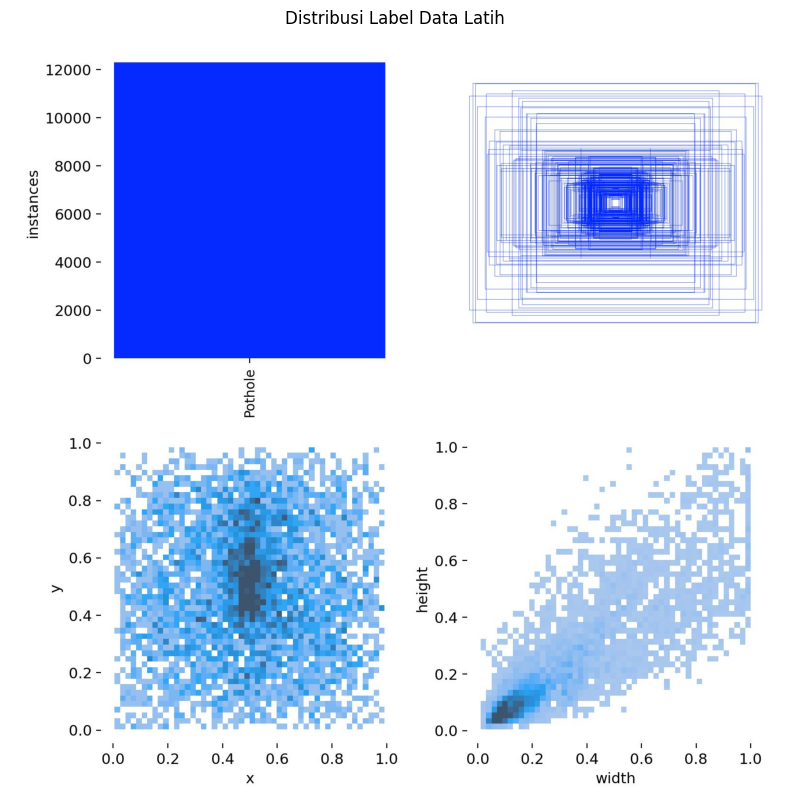

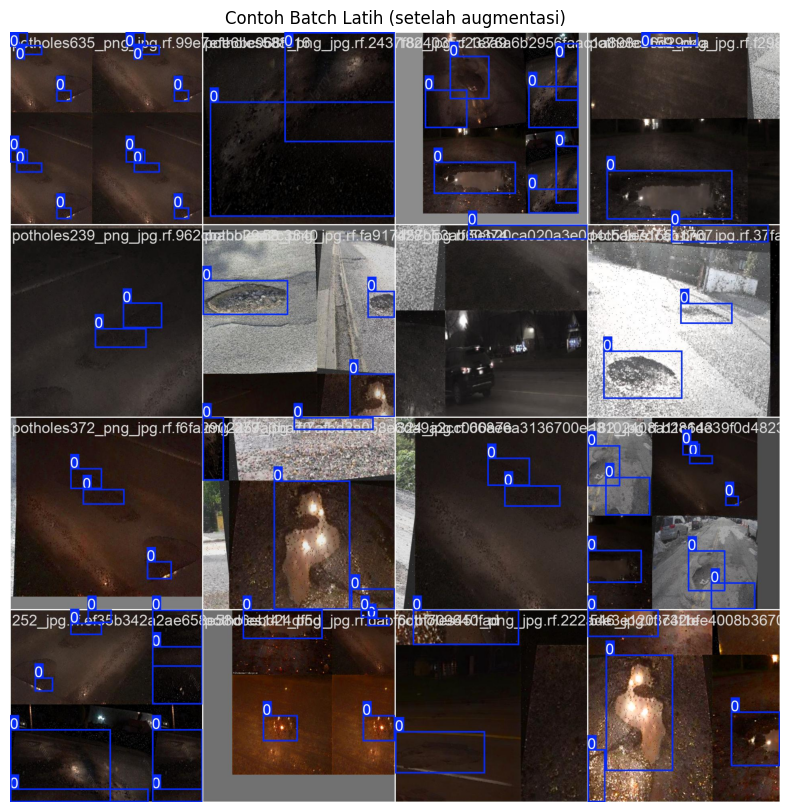

In [11]:
# Kurva Precision-confidence dan Recall-confidence pada data validasi
show_image(f"{results_dir}/P_curve.png", "Precision-Confidence Curve (Validasi)")
show_image(f"{results_dir}/R_curve.png", "Recall-Confidence Curve (Validasi)")

# Distribusi label pada data latih dan contoh batch latih setelah augmentasi
show_image(f"{results_dir}/labels.jpg", "Distribusi Label Data Latih")
show_image(f"{results_dir}/train_batch0.jpg", "Contoh Batch Latih (setelah augmentasi)")

## 8. Evaluasi pada data uji

Bobot terbaik (`best.pt`) dievaluasi pada split uji (100 citra malam NPD) dengan `split='test'`, `imgsz=640`, dan `batch=16`. mAP dihitung pada seluruh rentang confidence, sedangkan Precision dan Recall dilaporkan pada confidence yang menghasilkan F1 maksimum.

In [12]:
from ultralytics import YOLO
import os

best_model_path = f'runs/detect/{RUN_NAME}/weights/best.pt'
model = YOLO(best_model_path)

metrics = model.val(
    data=DATA_YAML,
    split='test',
    imgsz=640,
    batch=16,
    name=f'eval_test_{RUN_NAME}'
)

def get_metric(metrics_dict, keys):
    # Nama key berbeda antarversi Ultralytics
    for key in keys:
        if key in metrics_dict:
            return metrics_dict[key]
    return 0.0

res = metrics.results_dict
map50 = get_metric(res, ['metrics/map50', 'metrics/mAP50(B)'])
map95 = get_metric(res, ['metrics/map50-95', 'metrics/mAP50-95(B)'])
prec  = get_metric(res, ['metrics/precision', 'metrics/precision(B)'])
rec   = get_metric(res, ['metrics/recall', 'metrics/recall(B)'])

print("\n" + "="*30)
print("📈 HASIL EVALUASI DATA TEST")
print("="*30)
print(f"mAP50:       {map50:.4f}")
print(f"mAP50-95:    {map95:.4f}")
print(f"Precision:   {prec:.4f}")
print(f"Recall:      {rec:.4f}")
print("="*30)

Ultralytics 8.3.63 🚀 Python-3.13.15 torch-2.9.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 238 layers, 9,413,187 parameters, 0 gradients, 21.3 GFLOPs


val: Scanning /content/dataset/The aug/test/labels... 100 images, 0 backgrounds, 0 corrupt: 100%|██████████| 100/100 [00:00<00:00, 2022.16it/s]

val: New cache created: /content/dataset/The aug/test/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:03<00:00,  2.29it/s]


                   all        100        166       0.78      0.554      0.598      0.297
Speed: 0.3ms preprocess, 11.3ms inference, 0.0ms loss, 5.3ms postprocess per image
Results saved to runs/detect/eval_test_yolo11s_sintetis100

📈 HASIL EVALUASI DATA TEST
mAP50:       0.5979
mAP50-95:    0.2971
Precision:   0.7804
Recall:      0.5542


**Insight.**
- **Hasil uji:** Precision **0,7804**, Recall **0,5542**, mAP@0.5 **0,5979**, dan mAP@0.5:0.95 **0,2971**.
- **Perbandingan antarskenario YOLO11s:** mAP@0.5 hampir sama dengan baseline (0,5973) dan di bawah skenario sintetis 50% (0,6118). Precision-nya justru tertinggi di antara ketiga skenario YOLO11s, sedangkan Recall-nya sama dengan skenario 50%.
- **Kecepatan:** waktu inferensi pada data uji sekitar 13,1 ms per citra.


0: 640x640 1 Pothole, 17.2ms
1: 640x640 2 Potholes, 17.2ms
2: 640x640 1 Pothole, 17.2ms
Speed: 2.7ms preprocess, 17.2ms inference, 1.1ms postprocess per image at shape (1, 3, 640, 640)


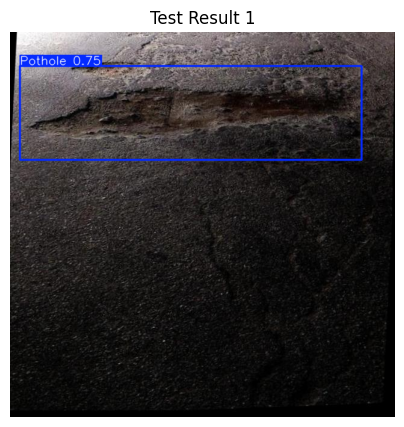

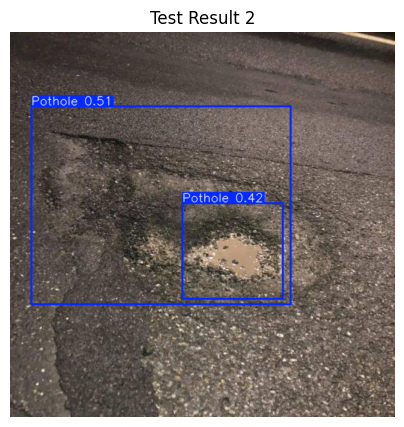

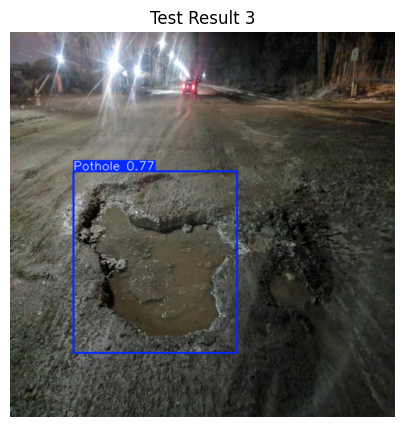

In [13]:
import glob
import yaml

# Contoh prediksi pada tiga citra pertama data uji (confidence 0,25)
with open(DATA_YAML, 'r') as f:
    config = yaml.safe_load(f)
test_files = glob.glob(os.path.join(config['test'], "*.jpg"))[:3]

results = model.predict(source=test_files, conf=0.25)

for i, r in enumerate(results):
    img_rgb = cv2.cvtColor(r.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(5, 5))
    plt.imshow(img_rgb)
    plt.title(f"Test Result {i+1}")
    plt.axis('off')
    plt.show()

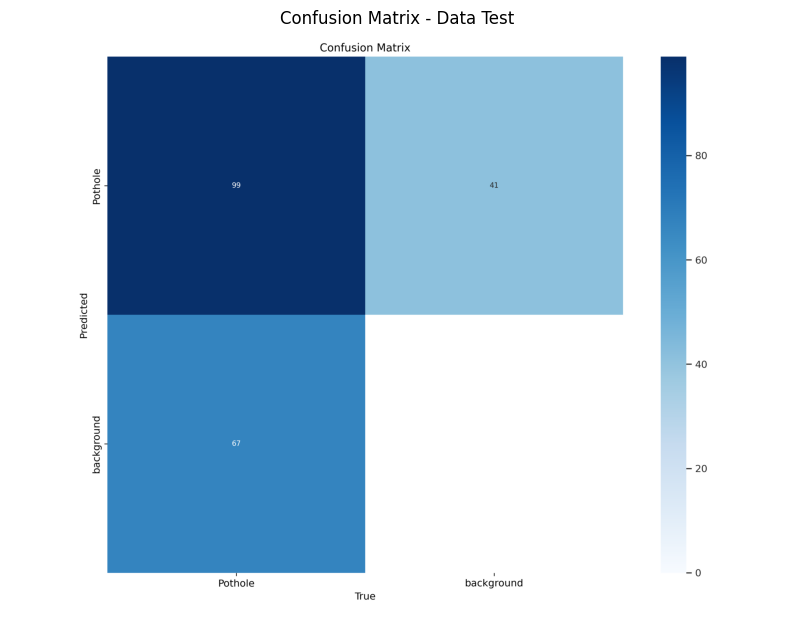

In [14]:
eval_test_dir = f'runs/detect/eval_test_{RUN_NAME}'

def show_eval_plot(directory, filename, title):
    path = os.path.join(directory, filename)
    if os.path.exists(path):
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(10, 8))
        plt.imshow(img)
        plt.title(title)
        plt.axis('off')
        plt.show()
    else:
        print(f"⚠️ File {filename} tidak ditemukan di {directory}. Pastikan model.val() sudah selesai.")

# Confusion matrix pada data uji
show_eval_plot(eval_test_dir, 'confusion_matrix.png', "Confusion Matrix - Data Test")

**Catatan.** Grafik ini tidak ditampilkan pada notebook asli, sehingga belum ada outputnya. Grafik akan muncul saat notebook dijalankan ulang.

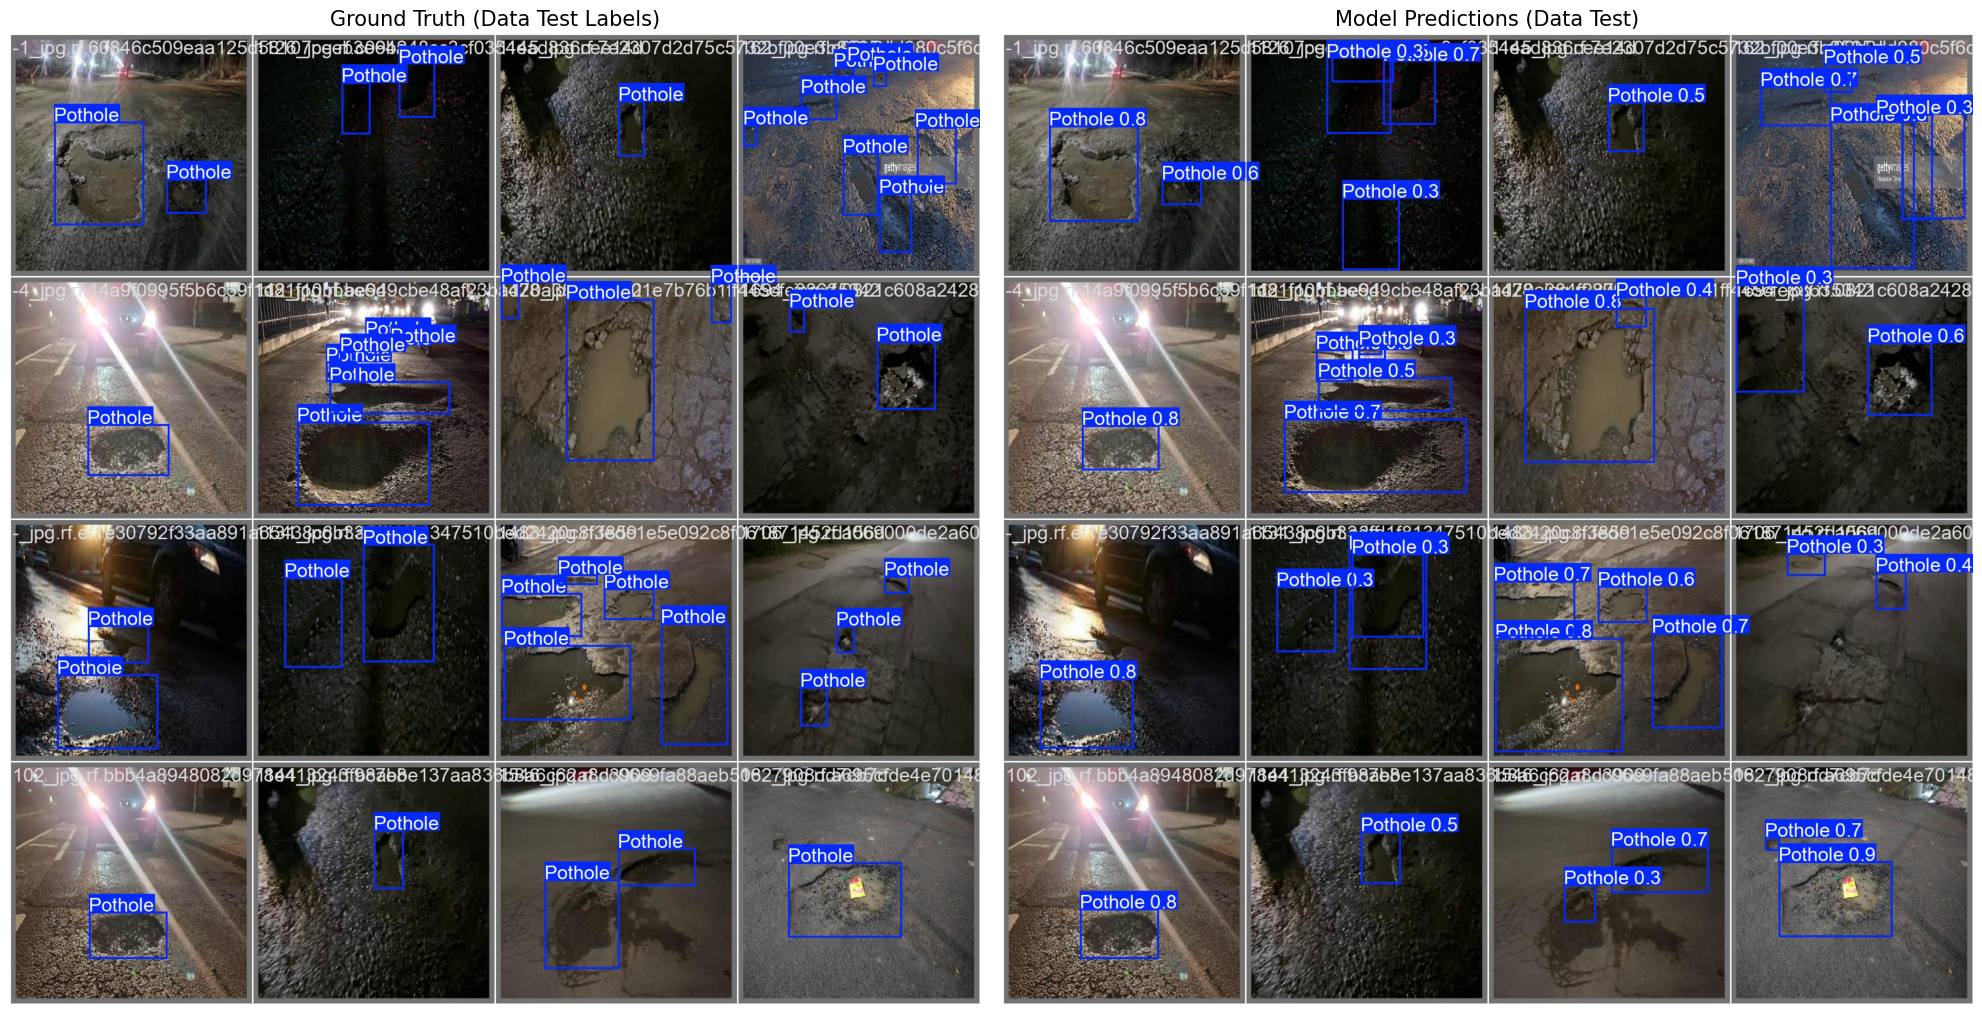

In [15]:
# Perbandingan label asli dan prediksi pada batch pertama data uji
# (Ultralytics tetap menamai file 'val_batch' walaupun split='test')
fig, axes = plt.subplots(1, 2, figsize=(20, 10))

gt_path = os.path.join(eval_test_dir, 'val_batch0_labels.jpg')
if os.path.exists(gt_path):
    axes[0].imshow(cv2.cvtColor(cv2.imread(gt_path), cv2.COLOR_BGR2RGB))
    axes[0].set_title("Ground Truth (Data Test Labels)", fontsize=15)
    axes[0].axis('off')
else:
    print("⚠️ File label batch tidak ditemukan.")

pred_path = os.path.join(eval_test_dir, 'val_batch0_pred.jpg')
if os.path.exists(pred_path):
    axes[1].imshow(cv2.cvtColor(cv2.imread(pred_path), cv2.COLOR_BGR2RGB))
    axes[1].set_title("Model Predictions (Data Test)", fontsize=15)
    axes[1].axis('off')
else:
    print("⚠️ File prediksi batch tidak ditemukan.")

plt.tight_layout()
plt.show()

### Kurva pada data uji

Kurva PR, F1, Precision, dan Recall terhadap confidence pada data uji, serta confusion matrix ternormalisasi.

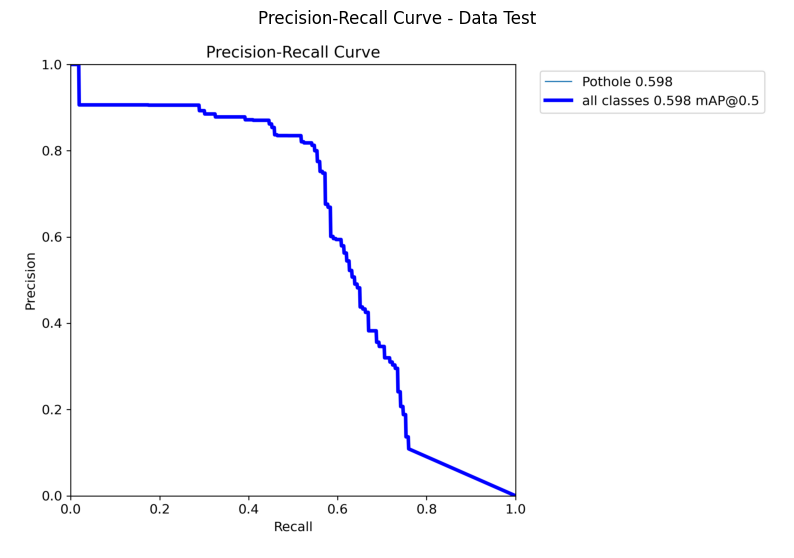

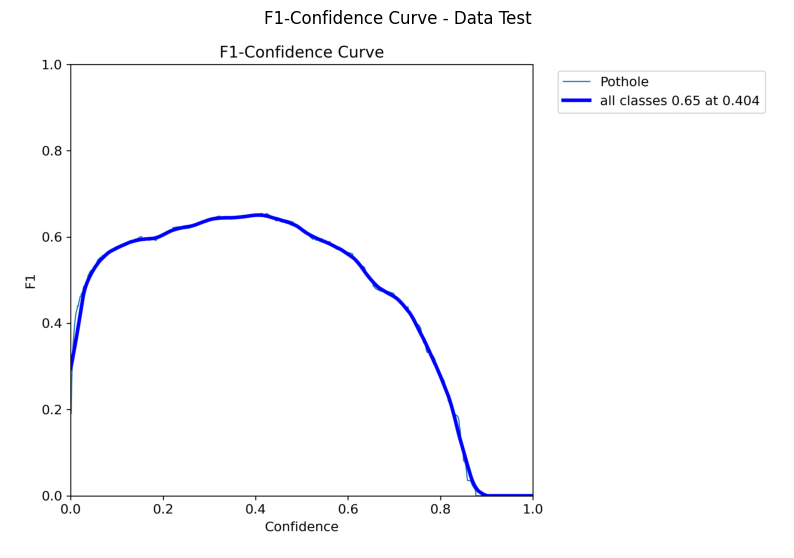

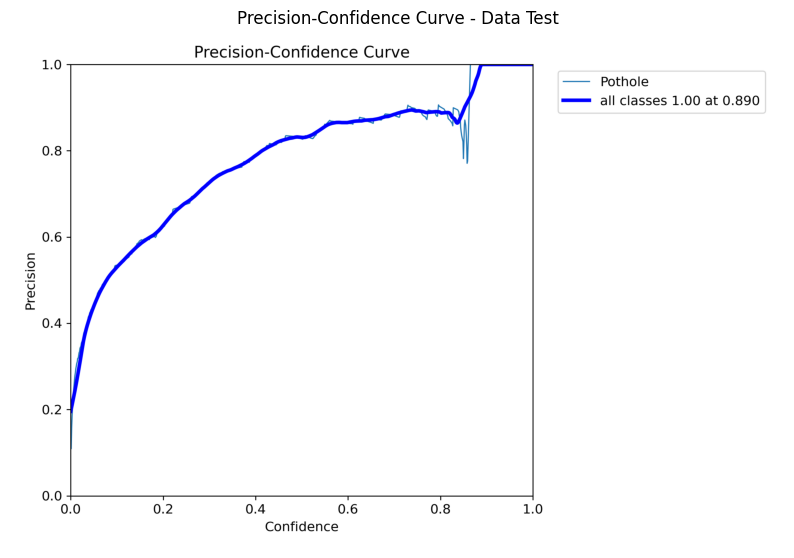

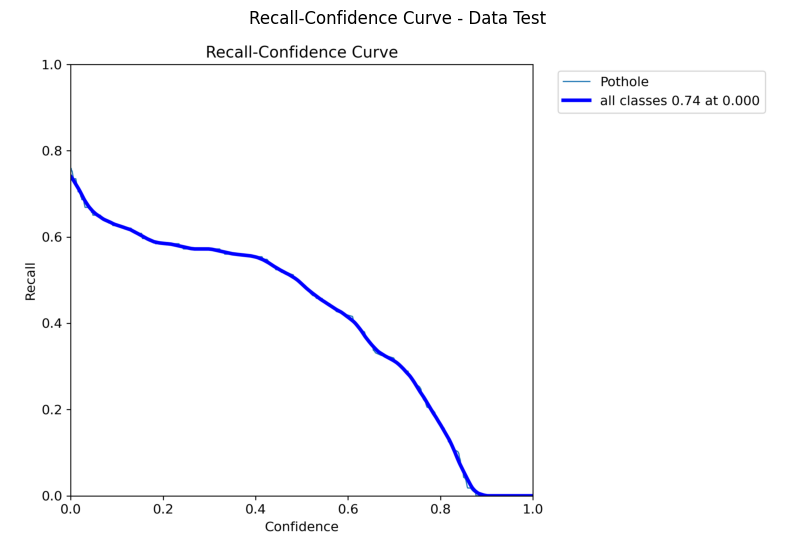

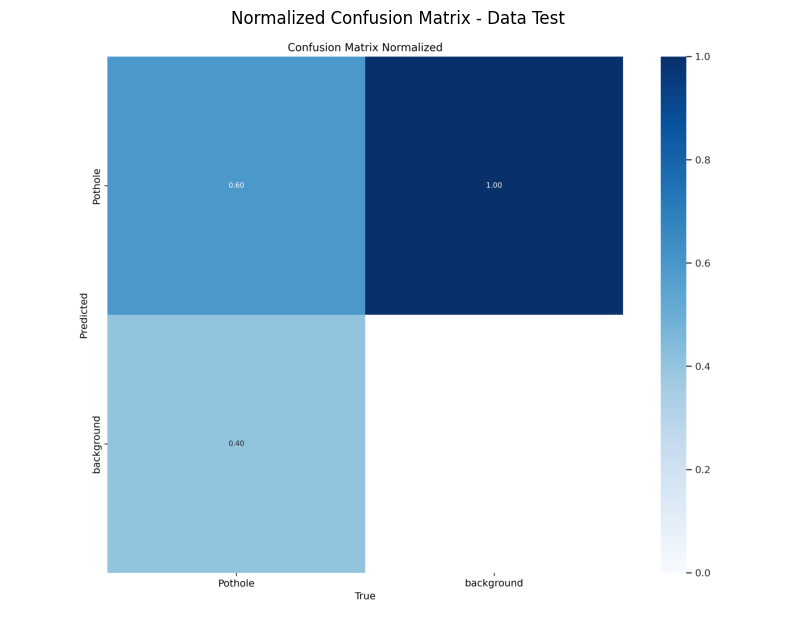

In [16]:
show_eval_plot(eval_test_dir, 'PR_curve.png', "Precision-Recall Curve - Data Test")
show_eval_plot(eval_test_dir, 'F1_curve.png', "F1-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'P_curve.png', "Precision-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'R_curve.png', "Recall-Confidence Curve - Data Test")
show_eval_plot(eval_test_dir, 'confusion_matrix_normalized.png', "Normalized Confusion Matrix - Data Test")

## 9. Ringkasan dan penyimpanan ke Google Drive

Sel pertama menyusun ringkasan metrik uji, jumlah parameter, kecepatan inferensi, dan versi lingkungan. Sel kedua menyimpan seluruh hasil ke Google Drive:

```
MyDrive/Output Yolo/<OUTPUT_GROUP>/<RUN_NAME>/
├── train/                  # folder hasil pelatihan (weights/best.pt, results.csv, kurva)
├── eval_test/              # folder hasil evaluasi pada data uji
└── summary_<RUN_NAME>.json # ringkasan metrik dan lingkungan
```

In [17]:
import json, sys
import torch, ultralytics

n_params = sum(p.numel() for p in model.model.parameters())
inf_ms = metrics.speed.get('inference', float('nan'))

summary = {
    "run": RUN_NAME,
    "model": MODEL_WEIGHTS.replace(".pt", ""),
    "scenario": SCENARIO,
    "dataset": DATASET_SLUG,
    "best_epoch": best_epoch,
    "params": int(n_params),
    "inference_ms_per_image": round(float(inf_ms), 2),
    "test": {
        "precision": round(float(prec), 4),
        "recall": round(float(rec), 4),
        "map50": round(float(map50), 4),
        "map50_95": round(float(map95), 4),
    },
    "environment": {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "cuda": torch.version.cuda,
        "ultralytics": ultralytics.__version__,
        "gpu": torch.cuda.get_device_name(0),
    },
}
print(json.dumps(summary, indent=2))

{
  "run": "yolo11s_sintetis100",
  "model": "yolo11s",
  "scenario": "Sintetis 100% (700 citra siang + 700 citra malam sintetis, augmentasi 3x)",
  "dataset": "pororozagi/aug-cycle",
  "best_epoch": 41,
  "params": 9413187,
  "inference_ms_per_image": 11.31,
  "test": {
    "precision": 0.7804,
    "recall": 0.5542,
    "map50": 0.5979,
    "map50_95": 0.2971
  },
  "environment": {
    "python": "3.13.15",
    "torch": "2.9.0+cu128",
    "cuda": "12.8",
    "ultralytics": "8.3.63",
    "gpu": "Tesla T4"
  }
}


In [18]:
import shutil
from google.colab import drive

drive.mount('/content/drive')
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 1. Folder hasil pelatihan (berisi weights/best.pt dan last.pt)
shutil.copytree(f'runs/detect/{RUN_NAME}', os.path.join(OUTPUT_DIR, 'train'), dirs_exist_ok=True)

# 2. Folder hasil evaluasi data uji
shutil.copytree(eval_test_dir, os.path.join(OUTPUT_DIR, 'eval_test'), dirs_exist_ok=True)

# 3. Ringkasan metrik
with open(os.path.join(OUTPUT_DIR, f'summary_{RUN_NAME}.json'), 'w') as f:
    json.dump(summary, f, indent=2)

print(f"✅ Hasil tersimpan di: {OUTPUT_DIR}")
for root, dirs, files_ in os.walk(OUTPUT_DIR):
    depth = root[len(OUTPUT_DIR):].count(os.sep)
    if depth <= 1:
        print("  " * depth + os.path.basename(root) + "/")

Mounted at /content/drive
✅ Hasil tersimpan di: /content/drive/MyDrive/Output Yolo/SOTA/yolo11s_sintetis100
yolo11s_sintetis100/
  train/
  eval_test/
